In [11]:
# Run this cell to activate or reset the panel buttons

# Python libraries
import os
import sys
import pickle
import networkx as nx
from io import StringIO
%matplotlib inline
import matplotlib.pyplot as plt
plt.close()

# IPython
import ipywidgets as widgets
from qgridnext import show_grid
from IPython.display import display

# ROTIFER
import rotifer
from rotifer.db import ncbi
from rotifer.db import uniprot
from rotifer.genome import utils as rgu
from rotifer.core import functions as rcf
from rotifer.interval import utils as riu
from rotifer.genome.data import NeighborhoodDF
from rotifer.devel.beta import hmmer as rdbh
from rotifer.devel.beta import sequence as rdbs
from rotifer.devel.alpha import gian_func as rdag
from rotifer.devel.alpha import epsoares as rdae
from rotifer.devel.alpha import rodolfo as rdar

# Subroutines
def new_id():
    from datetime import datetime
    return datetime.now().strftime("%Y%m%d%H%M%S")

def new_session(widget):
    sesText.value = new_id()

def get_session_path():
    from pathlib import Path
    return Path(".rotifer", sesText.value)

def on_dropdown_change(change):
  if change['type'] == 'change' and change['name'] == 'value':
    sesText.value = change["new"]

def show_who(widget):
    with output:
        try:
            output.clear_output()
            get_ipython().run_line_magic('who','')
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

def show_logfile(widget):
    with output:
        try:
            output.clear_output()
            print("Session ID     :",sesText.value)
            get_ipython().run_line_magic('logstate','')
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

def show_connection(widget):
    with output:
        try:
            output.clear_output()
            print(get_jupyter_server_list_output())
            print("\nThis kernel's connection info:")
            get_ipython().run_line_magic('connect_info','')
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

def clean_output(widget):
    with output:
        try:
            output.clear_output()
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

def get_jupyter_server_list_output():
    server_loaders = []
    
    # Check for modern or legacy server utility packages
    try:
        from jupyter_server.serverapp import list_running_servers
        server_loaders.append(list_running_servers)
    except ImportError:
        pass
    try:
        from notebook.notebookapp import list_running_servers
        server_loaders.append(list_running_servers)
    except ImportError:
        pass

    active_servers = []
    for load_servers in server_loaders:
        for server in load_servers():
            base_url = server.get("url", "")
            token = server.get("token", "")
            root_dir = server.get("root_dir", server.get("notebook_dir", "Unknown Directory"))
            
            # Format URL with token authentication key if it exists
            if token:
                full_url = f"{base_url}?token={token}"
            else:
                full_url = base_url
                
            active_servers.append(f"{full_url} :: {root_dir}")

    # Standard terminal layout mirroring the CLI tool
    if active_servers:
        output_text = "Currently running servers:\n" + "\n".join(active_servers)
    else:
        output_text = (
            "Currently running servers:\n"
            "No active standalone web servers found.\n"
            "(If you are using VS Code Native layout, it executes via direct Python subprocesses.)"
        )
    return output_text

# Bind and show
def display_panel():
    buttons = widgets.HBox([saveButton, clsButton, whoButton, logButton, connButton, initButton])
    display(buttons)
    buttons2 = widgets.HBox([sesText,sesCombo,newButton])
    display(buttons2)
    display(output)

# Get data
def get_saved_sessions():
    from pathlib import Path
    sessions = []
    if os.path.exists(".rotifer"):
        if os.path.isdir(".rotifer"):
            sessions = [ item for item in Path('.rotifer').iterdir() if item.is_dir() and (item / "session.dat").exists() ]
        else:
            print(".rotifer exists but it is not a directory!!!")
    sessions = [ item.name for item in sorted(sessions, key=lambda x: (x / "session.dat").stat().st_mtime, reverse=True) ]
    return sessions

# Operate on data: load, save, etc
def initialize(widget):
    with output:
        output.clear_output()  # Clean previous click
        try:
            sesdir = get_session_path()
            if not sesdir.exists():
                print(f"Directory for session {sesText.value} created at {str(sesdir)}")
                sesdir.mkdir(parents=True, exist_ok=True)
            if get_ipython().logger.logfile == None:
                i = 0
                logfile = sesdir / f"log.{i}.py"
                while logfile.exists():
                    i = i + 1
                    logfile = sesdir / f"log.{i}.py"
                get_ipython().run_line_magic('logstart',str(logfile))
                del(logfile)
            rcf.restore_session(sesdir / "session")
            get_ipython().run_line_magic('who','')
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

def save_session(widget):
    with output:
        try:
            output.clear_output()
            path = get_session_path()
            path.mkdir(parents=True, exist_ok=True)
            rcf.save_session(path / "session")
            sesCombo.options = get_saved_sessions()
            sesCombo.value = sesText.value
            print(f"Session saved!")
        except Exception as e:
            print(f"ERROR: {type(e).__name__}: {e}")

# Initialization before UI generation
_saved_sessions = get_saved_sessions()
if "_ROTIFER_SESSION_ID" not in globals():
    _ROTIFER_SESSION_ID = new_id()

# IPython widgets: create
output = widgets.Output()
newButton = widgets.Button(
    description="New session",
    button_style="success",
    icon="plus",
    tooltip="Create a new session"
)
initButton = widgets.Button(
    description="Reload",
    button_style="success",
    icon="refresh",
    tooltip="Replace data in memory with the last saved session"
)
saveButton = widgets.Button(
    description="Save",
    button_style="success",
    icon="floppy-o",
    tooltip="Save current session data"
)
whoButton  = widgets.Button(
    description="List",
    button_style="info",
    icon="list",
    tooltip="List variables, modules and functions"
)
logButton  = widgets.Button(
    description="Logstate",
    button_style="info",
    icon="history",
    tooltip="Show logging file name and info"
)
connButton = widgets.Button(
    description="Connection",
    button_style="info",
    icon="server",
    tooltip="Click to print the list of jupyter servers with auth tokens"
)
clsButton  = widgets.Button(
    description="Clear",
    button_style="info",
    icon="circle-thin",
    tooltip="Clear output"
)
sesCombo = widgets.Dropdown(
    options=_saved_sessions,
    description='Saved sessions:',
    disabled=False,
    style={'description_width': 'initial'},
    icon="check"
)
sesText = widgets.Text(
    placeholder='Rename current session',
    description='Session ID:',
    value=_saved_sessions[0] if len(_saved_sessions) > 0 else _ROTIFER_SESSION_ID,
    disabled=False
)

# Connect callbacks
newButton.on_click(new_session)
initButton.on_click(initialize)
saveButton.on_click(save_session)
whoButton.on_click(show_who)
logButton.on_click(show_logfile)
connButton.on_click(show_connection)
clsButton.on_click(clean_output)

# Attach the observer to the dropdown
sesCombo.observe(on_dropdown_change, names='value')

# Main
display_panel()

Output()

In [2]:
%who

NeighborhoodDF	 StringIO	 buttons	 display	 initButton	 initialize	 ncbi	 nx	 output	 
plt	 rcf	 rdag	 rdbh	 rgio	 rgu	 riu	 rotifer	 saveButton	 
save_session	 show_grid	 uniprot	 widgets	 


## We have a list of candidates for exploring VirB4 taken from Comparative genomics of the FtsK–HerA superfamily of pumping ATPases: implications for the origins of chromosome segregation, cell division and viral capsid packaging

|Query Acc |	Source |	Alternative Acc |	Info |
|----------|-----------|--------------------|----------|
|P0A3W0.1 |	Uniprot |		|Golden annotated accession of VirB4 in Agrobacterium tumefaciens 	|
|NP_223210.1 |	NCBI |	15611559; Q9ZLT4 |	Cage_E Hp - Deemed classical VirB4 by Aravind FtsK paper|
|AAM08240.1 	|NCBI |	19919310;Q8RPE5 |	lvhB4 |
|NP_220495.1 |	NCBI| 	15603980;Q9ZE45 |	RP103 |	
|NP_541005.1 |	NCBI |	17988372;Q8YDZ4 |	BMEII0028 |	
|NP_863348.1 |	NCBI |	32469876;Q8GJA2 |	VirB4 Cje |	
|T18339 |	NCBI |	7465640;Q5ZYB6 |	Icmb_Lepn IcMB |	
|NP_388375.1 |	NCBI |	16077561;P96642 |	YddE_Bs YddE | 	
|AAP22573.1 |	NCBI |	37955734 |	CP81_Pae CP81 |	
|NP_058238.1 |	NCBI |	10957214 |	TrhC_St TrhC |	
|ZP_00026649.1 |	NCBI |	22980948 |	Reut5675_Reme|

In [5]:
cagE = dict(data=rdbs.sequence(["WP_000496009.1"]))

local.easel: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.09s/it]


### Todo: embed actual molsession here
![Molstar view](Screenshot_20261102_163234.png)

In [8]:
# psiblast search on the whole protein
cagE["psi1"] = rdar.psiblast(cagE["data"], num_aln=5000, aln=False, db="/scratch/global/databases/fadb/uniprot/uniref50")

In [36]:
# We should investigate evalue and bitscore
# The result consists into a tuple, 0 is the hits table, 1 is the raw output of psiblast
cagE["psi1"][0].head(10)

,hit,query,hitstart,hitend,evalue,querycoverage,querystart,queryend,iteration,bitscore,length
0,UniRef50_Q48252,WP_000496009.1,1,983,0.000000e+00,1.000,1,983,1,2011.0,983
1,UniRef50_J0J980,WP_000496009.1,1,768,0.000000e+00,0.785,3,774,1,1552.0,768
2,UniRef50_UPI0022B2529A,WP_000496009.1,22,267,1.000000e-173,0.250,738,983,1,513.0,267
3,UniRef50_Q8GKD4,WP_000496009.1,1,209,1.000000e-140,0.213,287,495,1,426.0,209
4,UniRef50_A0A381F3V5,WP_000496009.1,6,923,3.000000e-119,0.952,46,981,1,395.0,923
5,UniRef50_UPI001F1056E8,WP_000496009.1,1,654,1.000000e-107,0.674,319,981,1,357.0,654
6,UniRef50_A0AA46RZP0,WP_000496009.1,1,922,4.000000e-98,0.962,35,980,1,338.0,922
7,UniRef50_A0AAV6EEL4,WP_000496009.1,24,928,7.000000e-98,0.954,41,978,1,338.0,929
8,UniRef50_UPI001E4E2E51,WP_000496009.1,33,717,4.000000e-93,0.705,286,978,1,320.0,718
9,UniRef50_A0A1X9T2X3,WP_000496009.1,134,932,2.000000e-92,0.826,167,978,1,323.0,935


In [39]:
# page(cagE["psi1"][1])
# uncomment the line above to see psiblast output

# Let's see usefull statistics!

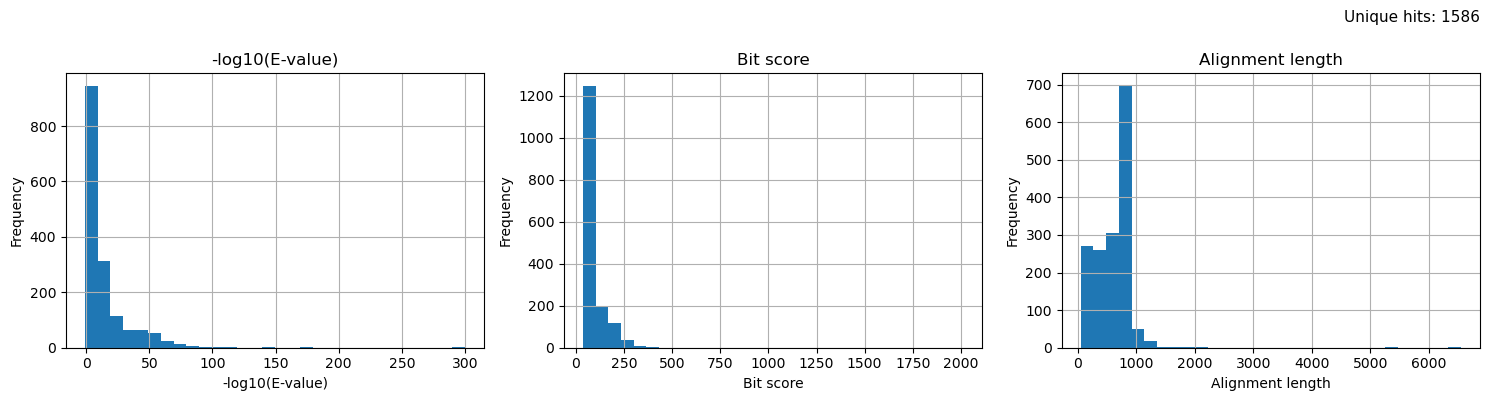

In [42]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cagE["psi1"][0].evalue.apply(
    lambda x: -np.log10(max(x, 1e-300))
).hist(ax=axes[0], bins=30)

cagE["psi1"][0].bitscore.hist(ax=axes[1], bins=30)
cagE["psi1"][0].length.hist(ax=axes[2], bins=30)

for ax, title in zip(axes, ["-log10(E-value)", "Bit score", "Alignment length"]):
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Frequency")

fig.text(
    0.99, 0.99,
    f"Unique hits: {cagE['psi1'][0].hit.nunique()}",
    ha="right", va="top", fontsize=11
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [ ]:
# Let's see distributions
cagE['psi1seqs'].add_cluster(cascade=[(100,100),(80,70),(80,50),(80,30),(0,0)], inplace=True)

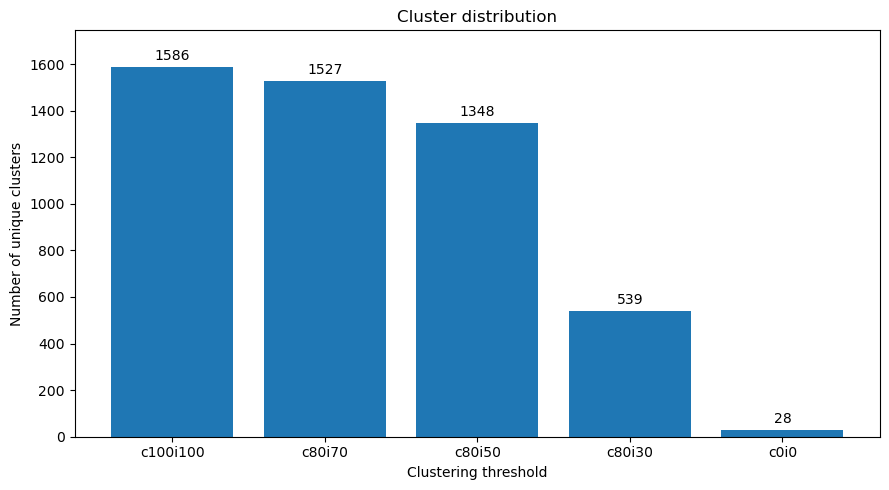

In [45]:
import matplotlib.pyplot as plt

cols = ["c100i100", "c80i70", "c80i50", "c80i30", "c0i0"]
counts = cagE['psi1seqs'].df[cols].nunique()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(counts.index, counts.values)

ax.bar_label(bars, padding=3)
ax.set_xlabel("Clustering threshold")
ax.set_ylabel("Number of unique clusters")
ax.set_title("Cluster distribution")
ax.set_ylim(0, counts.max() * 1.1)

plt.tight_layout()
plt.show()

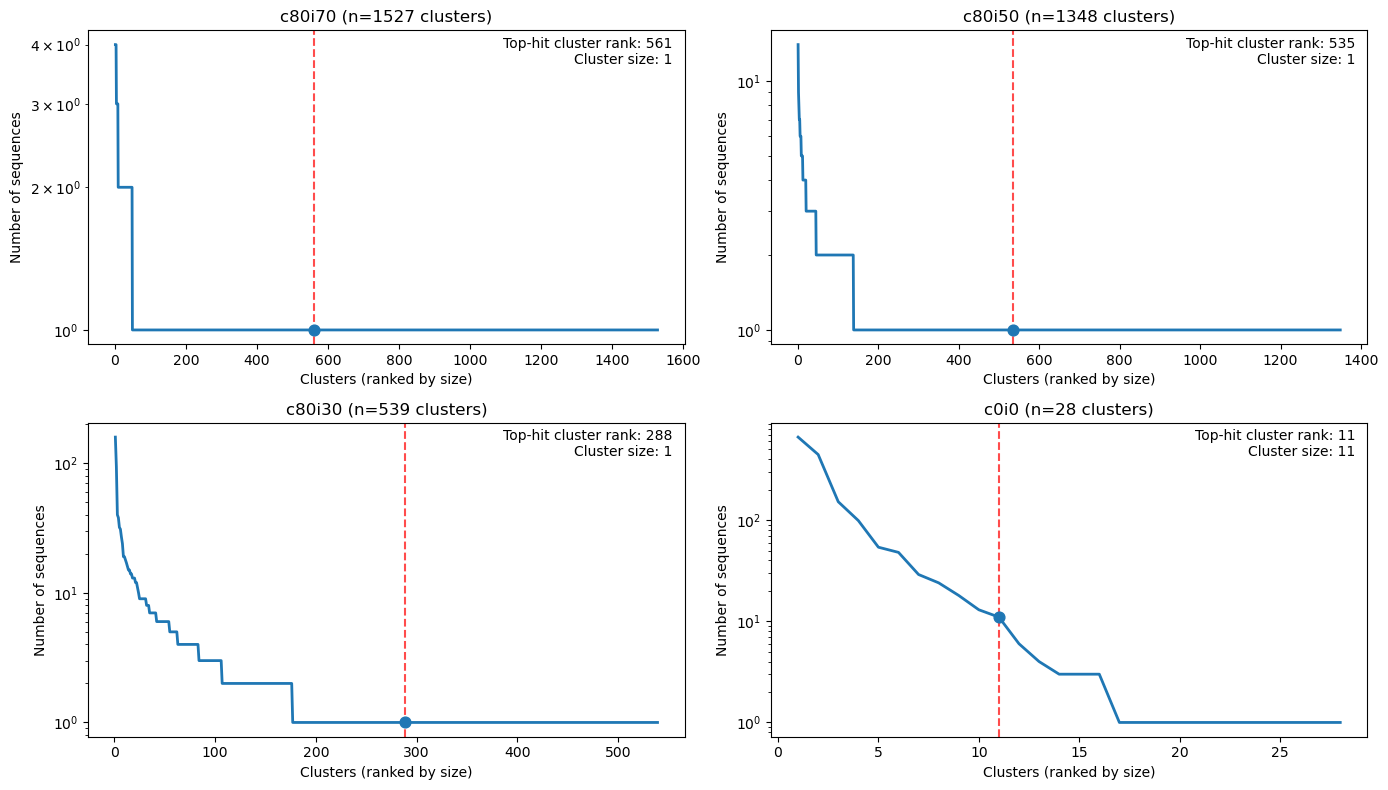

In [51]:
import numpy as np
import matplotlib.pyplot as plt

top_hit = cagE["psi1"][0].sort_values(
    ["evalue", "bitscore"],
    ascending=[True, False]
).iloc[0]["hit"]

seqs = cagE["psi1seqs"].df

ncols = 2 if len(cols) <= 4 else 3
nrows = (len(cols) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 4 * nrows), squeeze=False)

for ax, col in zip(axes.flat, cols):
    # cluster sizes sorted from largest to smallest
    sizes = seqs[col].value_counts()

    # cluster containing the top PSI-BLAST hit
    top_cluster = seqs.loc[seqs["id"] == top_hit, col].iloc[0]
    top_rank = sizes.index.get_loc(top_cluster) + 1   # 1-based rank
    top_size = sizes.loc[top_cluster]

    ranks = np.arange(1, len(sizes) + 1)

    # rank-size curve
    ax.plot(ranks, sizes.values, linewidth=2)

    # highlight the cluster containing the top hit
    ax.scatter(top_rank, top_size, s=60, zorder=3)
    ax.axvline(top_rank, color="red", linestyle="--", alpha=0.7)

    ax.set_title(f"{col} (n={len(sizes)} clusters)")
    ax.set_xlabel("Clusters (ranked by size)")
    ax.set_ylabel("Number of sequences")

    ax.text(
        0.98, 0.98,
        f"Top-hit cluster rank: {top_rank}\nCluster size: {top_size}",
        transform=ax.transAxes,
        ha="right", va="top"
    )

    # optional: helps when the distribution is very skewed
    ax.set_yscale("log")

# remove unused panels
for ax in list(axes.flat)[len(cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()